In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt

# Notebook 位於 C:\Lab\result，Excel 位於子資料夾 data
DATA_DIR = Path.cwd() / "data"

MODELS = (
    ("SFCN-reg T1", "SFCN_reg.xlsx", "T1WI"),
    ("SFCN-reg GM", "SFCN_reg.xlsx", "GMP"),
    ("SFCN-reg WM", "SFCN_reg.xlsx", "WMP"),
    ("SFCN-reg DGM", "SFCN_reg_dgm.xlsx", "DGM"),

    ("SFCN-sm T1", "SFCN_sm.xlsx", "T1WI"),
    ("SFCN-sm GM", "SFCN_sm.xlsx", "GMP"),
    ("SFCN-sm WM", "SFCN_sm.xlsx", "WMP"),
    ("SFCN-sm DGM", "SFCN_sm_dgm.xlsx",  "dgm"),
    # ("ResNet T1", "ResNet.xlsx", "T1"),
    # ("ResNet T1 B0", "ResNet.xlsx", "T1_B0"),
    # ("ResNet T1 SEX", "ResNet.xlsx", "T1_SEX"),
    # ("ResNet T1 SEX B0", "ResNet.xlsx", "T1_SEX_B0"),
)

# 對應 MATLAB 配色，依上方模型順序
# COLORS = (
#     (0.00, 0.45, 0.00), (0.20, 0.65, 0.25), (0.55, 0.80, 0.52),
#     (0.65, 0.00, 0.00), (0.88, 0.25, 0.25), (0.95, 0.45, 0.55),
#     (0.02, 0.00, 0.64), (0.25, 0.45, 0.85),
#     (0.30, 0.35, 0.80), (0.22, 0.64, 0.98),
# )

COLORS = (
    (0.65, 0.18, 0.20),  # SFCN-sm T1
    (0.87, 0.40, 0.30),  # SFCN-sm GM
    (0.90, 0.61, 0.26),  # SFCN-sm WM
    (0.71, 0.36, 0.64),  # SFCN-sm DGM

    (0.13, 0.30, 0.52),  # SFCN-reg T1
    (0.20, 0.49, 0.72),  # SFCN-reg GM
    (0.35, 0.67, 0.65),  # SFCN-reg WM
    (0.41, 0.40, 0.71),  # SFCN-reg DGM
)


OAS1_OVERLAP = {
    "OAS1_0061", "OAS1_0092", "OAS1_0111", "OAS1_0150", "OAS1_0156",
    "OAS1_0202", "OAS1_0230", "OAS1_0353", "OAS1_0368", "OAS1_0379",
}
MMRR_EXCLUDE = {"sub_502", "sub_742"}

In [5]:
def load_data(dataset, filename, suffix):
    df = pd.read_excel(
        DATA_DIR / filename,
        sheet_name=f"{dataset}_{suffix}",
        usecols=["Subject ID", "True Age", "Predicted Age", "pair"],
    )
    df = df.dropna(subset=["Subject ID", "True Age", "Predicted Age", "pair"]).copy()
    df["Pair"] = df["pair"].astype(str).str.replace(r"\.0$", "", regex=True)
    # 每一 pair 恰有 Scan 1 和 Scan 2
    df["Scan"] = df.groupby("Pair", sort=False).cumcount() + 1
    if not df.groupby("Pair").size().eq(2).all():
        raise ValueError(f"Pair 格式異常：{dataset} / {filename} / {suffix}")
    return df


def calculate_mae(df):
    # MAE = sum(|TrueAge - PredAge|) / n_scans
    return (df["True Age"] - df["Predicted Age"]).abs().mean()


def get_pairs(df):
    return df.pivot(index="Pair", columns="Scan", values="Predicted Age")


def calculate_mad(df):
    # MAD = sum(|PredAge_1 - PredAge_2|) / n_pairs
    p = get_pairs(df)
    return (p[1] - p[2]).abs().mean()


def calculate_icc(df):
    # ICC(2,1) = (MSB-MSE) / [MSB + (k-1)*MSE + (k/n)*(MSW-MSE)]
    # k=2; n=受試者配對數; MSB/ MSW/ MSE 為 two-way ANOVA 均方
    result = pg.intraclass_corr(
        data=df.rename(columns={"Predicted Age": "Pred"}),
        targets="Pair", raters="Scan", ratings="Pred",
    )
    # 支援 Pingouin 新版 ICC(A,1) 與舊版 ICC2 的欄名
    target = "ICC(A,1)" if "ICC(A,1)" in result["Type"].values else "ICC2"
    row = result.loc[result["Type"].eq(target)].iloc[0]
    ci_col = "CI95" if "CI95" in result.columns else "CI95%"
    return float(row["ICC"]), row[ci_col]


def calculate_maclaren_sd(df):
    df = df.copy()
    df["Subject"] = df["Subject ID"].str.extract(r"^(sub-\d+)_run-")
    result = {}
    intra_values, total_values = [], []
    for s in range(1, 4):
        sub = df.loc[df["Subject"].eq(f"sub-{s:02d}")]
        p = get_pairs(sub)
        # SD_intra = sqrt(sum((Pred1-Pred2)^2)/(2*m)), m=20 sessions
        sd_intra = np.sqrt(((p[1] - p[2]) ** 2).sum() / (2 * len(p)))
        # SD_total = sqrt(sum((Pred-mean(Pred))^2)/(N-1)), N=40 scans
        sd_total = sub["Predicted Age"].std(ddof=1)
        result[f"Sub{s} intra/total"] = f"{sd_intra:.3f} / {sd_total:.3f}"
        intra_values.append(sd_intra)
        total_values.append(sd_total)
    result["Mean SD intra"] = np.mean(intra_values)
    result["Mean SD total"] = np.mean(total_values)
    # Delta SD = mean(SD_total) - mean(SD_intra)
    result["Delta SD"] = result["Mean SD total"] - result["Mean SD intra"]
    return result


def fmt_pair(full, clean):
    return f"{full:.3f} ({clean:.3f})"


def fmt_ci(ci):
    return f"[{ci[0]:.3f}, {ci[1]:.3f}]"

In [7]:
def calculate_metrics(dataset, model, filename, suffix):
    df = load_data(dataset, filename, suffix)
    mae, mad = calculate_mae(df), calculate_mad(df)
    row = {
        "Model": model, "N scans": len(df), "N pairs": len(get_pairs(df)),
        "MAE": f"{mae:.3f}", "MAD": f"{mad:.3f}",
    }
    # 繪圖使用未經四捨五入的數值
    point = {"Dataset": dataset, "Model": model, "MAE": mae, "MAD": mad}

    if dataset == "Maclaren":
        row.update(calculate_maclaren_sd(df))
        return row, point

    icc, ci = calculate_icc(df)
    row["ICC(2,1)"] = f"{icc:.3f}"
    row["95% CI"] = fmt_ci(ci)

    if dataset == "OAS1" and model.startswith("ResNet"):
        subject = df["Subject ID"].str.replace(r"_MR\d+$", "", regex=True)
        is_mr1 = df["Subject ID"].str.endswith("_MR1")
        # MAE：只排除訓練見過的 10 筆 MR1；40 -> 30 scans
        mae_df = df.loc[~(subject.isin(OAS1_OVERLAP) & is_mr1)]
        # MAD/ICC：排除 overlap 受試者完整配對；20 -> 10 pairs
        pair_df = df.loc[~df["Pair"].isin(OAS1_OVERLAP)]
        clean_mae, clean_mad = calculate_mae(mae_df), calculate_mad(pair_df)
        clean_icc, clean_ci = calculate_icc(pair_df)
        row["N scans"] = f"{len(df)} ({len(mae_df)})"
        row["N pairs"] = f"{len(get_pairs(df))} ({len(get_pairs(pair_df))})"
        row["MAE"] = fmt_pair(mae, clean_mae)
        row["MAD"] = fmt_pair(mad, clean_mad)
        row["ICC(2,1)"] = fmt_pair(icc, clean_icc)
        row["95% CI"] = f"{fmt_ci(ci)} ({fmt_ci(clean_ci)})"
        point["MAE"], point["MAD"] = clean_mae, clean_mad

    elif dataset == "MMRR":
        subject = df["Subject ID"].str.extract(r"^(sub_\d+)")[0]
        # MAE：排除 sub_502、sub_742，共 4 scans；42 -> 38
        # MAD/ICC：全部 21 pairs，不排除
        mae_df = df.loc[~subject.isin(MMRR_EXCLUDE)]
        clean_mae = calculate_mae(mae_df)
        row["N scans"] = f"{len(df)} ({len(mae_df)})"
        row["MAE"] = fmt_pair(mae, clean_mae)
        point["MAE"] = clean_mae

    return row, point

In [8]:
tables = {}
points = []
for dataset in ("Maclaren", "OAS1", "MMRR"):
    rows = []
    for model, filename, suffix in MODELS:
        row, point = calculate_metrics(dataset, model, filename, suffix)
        rows.append(row)
        points.append(point)
    tables[dataset] = pd.DataFrame(rows)
    print(f"\n========== {dataset} ==========")
    print(tables[dataset].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

plot_df = pd.DataFrame(points)


========== Maclaren ==========
       Model  N scans  N pairs   MAE   MAD Sub1 intra/total Sub2 intra/total Sub3 intra/total  Mean SD intra  Mean SD total  Delta SD
 SFCN-reg T1      120       60 1.238 1.039    0.906 / 0.978    0.999 / 1.159    0.704 / 0.839          0.870          0.992     0.122
 SFCN-reg GM      120       60 2.711 1.066    1.033 / 1.017    0.921 / 1.030    0.718 / 0.965          0.890          1.004     0.114
 SFCN-reg WM      120       60 1.970 1.895    1.288 / 1.238    1.757 / 1.849    2.088 / 1.878          1.711          1.655    -0.056
SFCN-reg DGM      120       60 2.787 1.968    1.276 / 1.858    2.390 / 2.200    1.362 / 1.354          1.676          1.804     0.128
  SFCN-sm T1      120       60 4.328 1.114    1.336 / 1.670    0.782 / 0.928    0.852 / 0.998          0.990          1.198     0.208
  SFCN-sm GM      120       60 4.054 0.918    0.657 / 0.762    1.000 / 1.026    0.798 / 0.818          0.818          0.869     0.050
  SFCN-sm WM      120       60

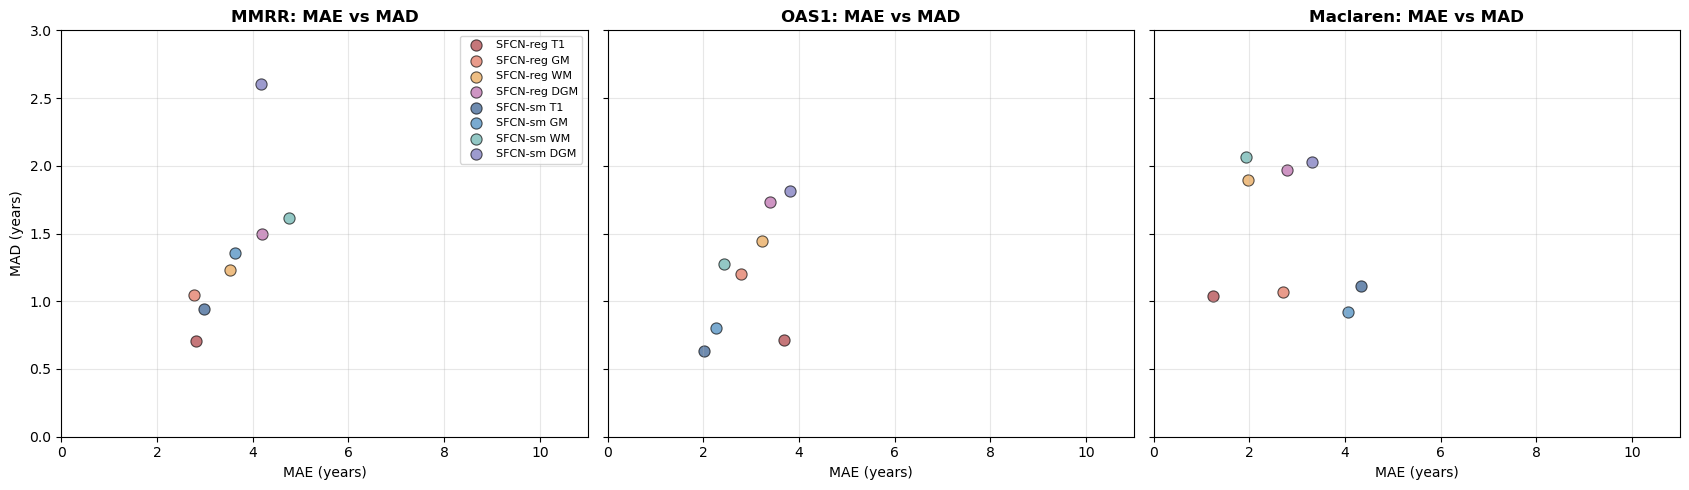

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)

for ax, dataset in zip(axes, ("MMRR", "OAS1", "Maclaren")):
    data = plot_df.loc[plot_df["Dataset"].eq(dataset)].set_index("Model")
    for (model, _, _), color in zip(MODELS, COLORS):
        ax.scatter(data.loc[model, "MAE"], data.loc[model, "MAD"],
                   s=65, color=color, edgecolors="black", linewidths=0.8, alpha= 0.65,
                   label=model)
    ax.set_title(f"{dataset}: MAE vs MAD", fontweight="bold")
    ax.set_xlabel("MAE (years)")
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 3)

axes[0].set_ylabel("MAD (years)")
axes[0].legend(loc="upper right", fontsize=8, frameon=True)
fig.tight_layout()
plt.show()

In [10]:
# Maclaren: 60 subject-session scan pairs 的探索性 ICC(2,1) 與 95% CI
# 注意：同一受試者的 20 個 sessions 彼此相關，此 ICC 僅作描述性分析。
maclaren_icc_rows = []

for model, filename, suffix in MODELS:
    df = load_data("Maclaren", filename, suffix)
    n_pairs = df["Pair"].nunique()
    if n_pairs != 60 or len(df) != 120:
        raise ValueError(f"{model}: 預期 Maclaren 為 60 pairs、120 scans，實際為 {n_pairs} pairs、{len(df)} scans")

    # Pair = 同一受試者同一 session 的兩次 scans；Scan = 1 或 2
    icc, ci = calculate_icc(df)
    maclaren_icc_rows.append({
        "Model": model,
        "N pairs": n_pairs,
        "ICC(2,1)": round(icc, 3),
        "95% CI": fmt_ci(ci),
    })

maclaren_icc_table = pd.DataFrame(maclaren_icc_rows)
print("Maclaren ICC(2,1): 60 subject-session pairs (descriptive only)")
print("Caution: 60 pairs are nested in 3 subjects; Pingouin CI assumes independent targets.")
print(maclaren_icc_table.to_string(index=False))


Maclaren ICC(2,1): 60 subject-session pairs (descriptive only)
Caution: 60 pairs are nested in 3 subjects; Pingouin CI assumes independent targets.
       Model  N pairs  ICC(2,1)         95% CI
 SFCN-reg T1       60     0.926 [0.880, 0.960]
 SFCN-reg GM       60     0.328 [0.080, 0.540]
 SFCN-reg WM       60     0.792 [0.670, 0.870]
SFCN-reg DGM       60     0.647 [0.470, 0.770]
  SFCN-sm T1       60     0.777 [0.650, 0.860]
  SFCN-sm GM       60     0.889 [0.820, 0.930]
  SFCN-sm WM       60     0.471 [0.250, 0.640]
 SFCN-sm DGM       60     0.398 [0.160, 0.590]
